# 01 - Data preparation: NASA Milling run-to-failure data

**Machine:** Matsuura MC-510V CNC machining center (UC Berkeley experiment, NASA PCoE data repository).

The experiment ran **16 tools** (cases) from new to worn. After some cuts (runs), the machine was stopped
and the tool **flank wear VB** was measured under a microscope. During every cut, 6 sensors were recorded:

| Sensor | What it sees |
|---|---|
| spindle motor current AC / DC | the motor works harder when the tool is blunt |
| vibration (table, spindle) | chatter, imbalance |
| acoustic emission (table, spindle) | friction and micro-cracks at the cutting edge |

This is **run-to-failure** data: we can see the degradation over time, which is what predictive maintenance needs.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.io

from features import load_mill_runs, add_relative_features, SIGNALS, SIGNAL_NAMES, WEAR_LIMIT_MM

## 1. What does one cut look like?

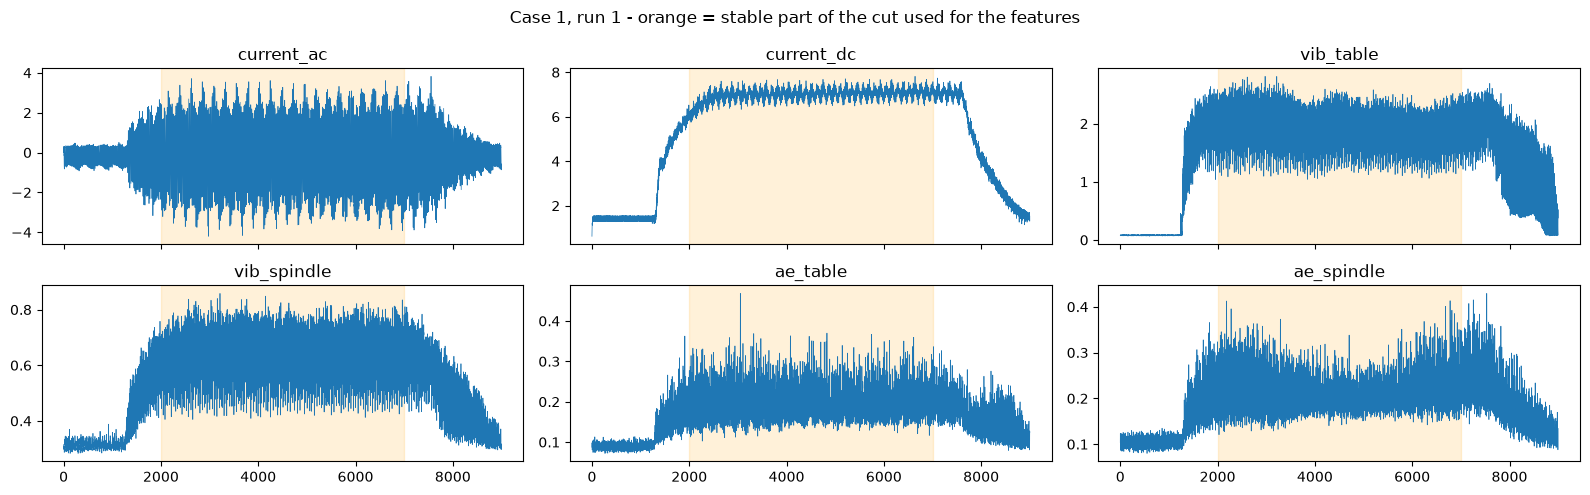

In [2]:
raw = scipy.io.loadmat("../data/mill.mat")["mill"][0]
run = raw[0]

fig, axes = plt.subplots(2, 3, figsize=(16, 5), sharex=True)
for ax, (mat_name, name, _) in zip(axes.ravel(), SIGNALS):
    ax.plot(run[mat_name].ravel(), lw=0.5)
    ax.axvspan(2000, 7000, color="orange", alpha=0.15)
    ax.set_title(name)
fig.suptitle("Case 1, run 1 - orange = stable part of the cut used for the features")
plt.tight_layout()

## 2. One row per cut

Each sensor is summarised by one number (RMS or mean of the stable part).

In [3]:
df = load_mill_runs("../data/mill.mat")
print(len(df), "runs,", df["case"].nunique(), "tools")
df.head()

167 runs, 16 tools


,case,run,cut_time,wear_mm,doc,feed,material,current_ac,current_dc,vib_table,vib_spindle,ae_table,ae_spindle
0,1,1,2.0,0.00,1.5,0.5,1,1.803723,6.973506,0.268517,0.078425,0.198521,0.212475
1,1,2,4.0,NaN,1.5,0.5,1,1.845319,7.129255,0.252902,0.077745,0.203323,0.210292
2,1,3,6.0,NaN,1.5,0.5,1,1.872368,7.232434,0.236742,0.087101,0.204757,0.235549
3,1,4,7.0,0.11,1.5,0.5,1,1.941348,7.495454,0.228656,0.059546,0.215903,0.237490
4,1,5,11.0,NaN,1.5,0.5,1,2.202814,8.498305,0.182343,0.036392,0.229876,0.255197


## 3. Cleaning

Some runs contain sensor glitches (values far outside the normal range). Real plant data always has this.

In [4]:
df[SIGNAL_NAMES].describe().round(3)

,current_ac,current_dc,vib_table,vib_spindle,ae_table,ae_spindle
count,167.000,167.000,167.000,167.000,167.000,167.000
mean,2.173,7.234,0.515,0.018,0.203,0.251
std,2.966,2.104,4.275,0.014,0.066,0.085
min,0.903,0.554,0.036,0.000,0.000,0.000
25%,1.411,5.562,0.125,0.011,0.161,0.191
50%,1.841,7.179,0.176,0.013,0.196,0.233
75%,2.405,9.406,0.227,0.018,0.244,0.302
max,39.187,9.995,55.413,0.087,0.387,0.516


In [5]:
glitch = (df["current_ac"] > 5) | (df["current_dc"] < 1) | (df["ae_table"] < 0.01)
print("Glitched runs:", df.loc[glitch, ["case", "run"]].values.tolist())
df = df[~glitch].reset_index(drop=True)

Glitched runs: [[12, 1]]


## 4. How the tools wear

Classic wear curve: fast at the start (break-in), then steady, then accelerating at the end.
The red line is the **end-of-life limit** (0.5 mm). Tools wear at very different speeds depending on the job.

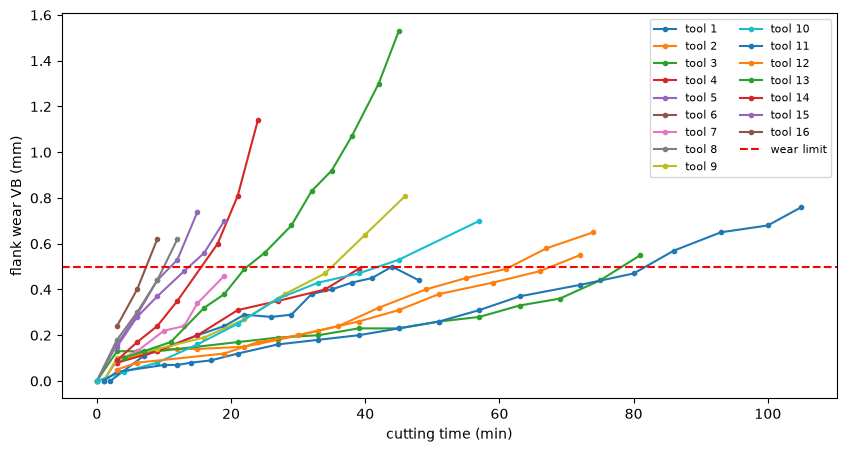

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
for case, tool in df.dropna(subset=["wear_mm"]).groupby("case"):
    ax.plot(tool["cut_time"], tool["wear_mm"], marker="o", ms=3, label=f"tool {case}")
ax.axhline(WEAR_LIMIT_MM, color="red", ls="--", label="wear limit")
ax.set_xlabel("cutting time (min)"); ax.set_ylabel("flank wear VB (mm)")
ax.legend(ncol=2, fontsize=8);

## 5. Compare each tool with itself when it was new

The raw signal level depends a lot on the job (material, depth of cut). Dividing by the value of the
**first cut of the same tool** removes that effect. This is the usual "baseline after tool change" of
condition monitoring systems.

In [7]:
df = add_relative_features(df)
rel = [f"{name}_rel" for name in SIGNAL_NAMES]

comparison = pd.DataFrame({
    "raw signal": df[SIGNAL_NAMES + ["wear_mm"]].corr()["wear_mm"].drop("wear_mm").values,
    "relative to new tool": df[rel + ["wear_mm"]].corr()["wear_mm"].drop("wear_mm").values,
}, index=SIGNAL_NAMES)
comparison.round(2)

,raw signal,relative to new tool
current_ac,0.60,0.82
current_dc,0.63,0.72
vib_table,-0.31,-0.10
vib_spindle,-0.16,-0.11
ae_table,0.42,0.66
ae_spindle,0.33,0.64


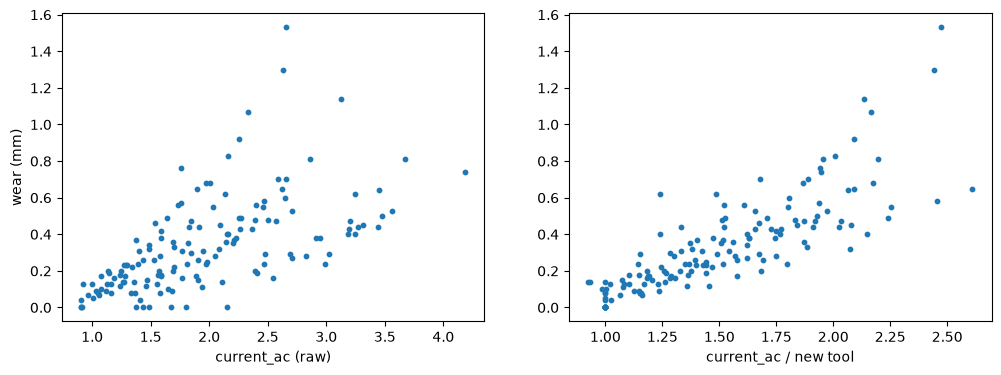

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(df["current_ac"], df["wear_mm"], s=10); axes[0].set_xlabel("current_ac (raw)")
axes[1].scatter(df["current_ac_rel"], df["wear_mm"], s=10); axes[1].set_xlabel("current_ac / new tool")
axes[0].set_ylabel("wear (mm)");

## 6. Remaining Useful Life (RUL) label

For every tool that reached the limit, find **when** it crossed 0.5 mm (linear interpolation between
two measurements). Then `RUL = failure time - current cutting time`.

In [9]:
def failure_time(tool):
    measured = tool.dropna(subset=["wear_mm"])
    if measured["wear_mm"].max() < WEAR_LIMIT_MM:
        return np.nan  # this tool never reached the limit
    return float(np.interp(WEAR_LIMIT_MM, measured["wear_mm"].cummax(), measured["cut_time"]))

fail_at = df.groupby("case").apply(failure_time, include_groups=False)
df["failure_time"] = df["case"].map(fail_at)
df["rul_min"] = df["failure_time"] - df["cut_time"]
df.loc[df["rul_min"] < 0, "rul_min"] = np.nan  # after the limit: already failed

fail_at.round(1).rename("failure time (min)").to_frame().T

case,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
failure time (min),48.0,67.7,78.3,NaN,11.0,NaN,NaN,10.0,35.1,42.0,81.8,61.7,22.4,15.6,13.8,7.4


## 7. Save

In [10]:
df.to_csv("../data/milling_features.csv", index=False)
print("Saved", len(df), "runs")
df.head()

Saved 166 runs


,case,run,cut_time,wear_mm,doc,feed,material,current_ac,current_dc,vib_table,...,ae_table,ae_spindle,current_ac_rel,current_dc_rel,vib_table_rel,vib_spindle_rel,ae_table_rel,ae_spindle_rel,failure_time,rul_min
0,1,1,2.0,0.00,1.5,0.5,1,1.803723,6.973506,0.268517,...,0.198521,0.212475,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,48.0,46.0
1,1,2,4.0,NaN,1.5,0.5,1,1.845319,7.129255,0.252902,...,0.203323,0.210292,1.023061,1.022334,0.941846,0.991330,1.024190,0.989726,48.0,44.0
2,1,3,6.0,NaN,1.5,0.5,1,1.872368,7.232434,0.236742,...,0.204757,0.235549,1.038057,1.037130,0.881665,1.110623,1.031416,1.108596,48.0,42.0
3,1,4,7.0,0.11,1.5,0.5,1,1.941348,7.495454,0.228656,...,0.215903,0.237490,1.076300,1.074847,0.851549,0.759271,1.087559,1.117736,48.0,41.0
4,1,5,11.0,NaN,1.5,0.5,1,2.202814,8.498305,0.182343,...,0.229876,0.255197,1.221259,1.218656,0.679073,0.464035,1.157946,1.201070,48.0,37.0
